# Biodiversity Challenge Benchmark Notebook     

## Model Objective
<p align="justify">The objective of this model is to predict the presence of frog species on the basis of TerraClimate variables extracted from the Microsoft Planetary data catalog, which provides data for monthly climate and climatic water balance across global terrestrial surfaces from 1958 to the present.  
</p>

## Datasets used

#### 1. Frog presence Data
The dataset provides information about the presence of frogs across Australia over a period of 2 years from Nov'2017 to Nov'2019.

Data Source : [Global Biodiversity Information Facility](https://www.gbif.org/) portal.

#### 2.  Climate Data
TerraClimate data from Micorosoft Planetary catalog which provides monthly climate and climatic water balance for global terrestrial surfaces from 1958 to the present. The data provide important inputs for ecological and hydrological studies at global scales that require high spatial resolution and time-varying data.

Data Source : [Terraclimate dataset](https://planetarycomputer.microsoft.com/dataset/terraclimate) from the Microsoft Planetary Computer portal.

<br>
<br>

## Load In Dependencies

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data science 
import pandas as pd
import numpy as np

# Feature engineering
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold


# Multi-dimensional arrays and datasets
import xarray as xr

# Geospatial data analysis
import geopandas as gpd

# Geospatial operations
import rasterio

# Machine Learning
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

# Others
import os
from tqdm import tqdm
import sys

## Load data

### 1. Response Variable

In [2]:
# Load the training data from csv file and display the first few rows to inspect the data
ground_df = pd.read_csv("../data/raw/Training_Data.csv")
ground_df.head()

,ID,Latitude,Longitude,Occurrence Status
0,ID_TR_957A5A,-34.027900,150.771000,1
1,ID_TR_55E0AF,-34.821595,147.193697,1
2,ID_TR_7AC931,-36.617759,146.882941,0
3,ID_TR_7D3CE4,-37.470900,144.744000,1
4,ID_TR_02F669,-38.400153,145.018560,1


In [3]:
#Check dataframe shape.
ground_df.shape

(6312, 4)

### 2. Predictor Variables

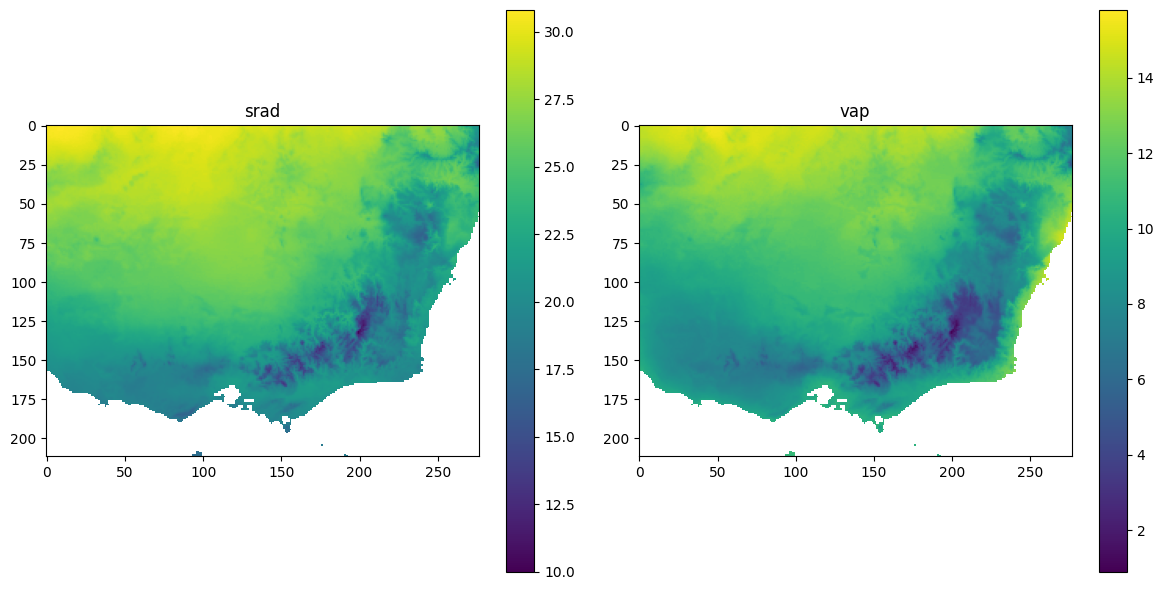

In [4]:
# Reads and plots two climatic parameters srad and vap from the GeoTIFF file.

# Open the GeoTIFF file
tiff_path = "../data/interim/TerraClimate_output.tiff"

# Read the variables from the GeoTIFF file
with rasterio.open(tiff_path) as src1:
    variable1 = src1.read(1)  # variable [srad]
    variable2 = src1.read(2)  # variable [vap]

# Plot the variables in a 2x2 grid
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Flatten the axes for easier indexing
axes = axes.flatten()

# Plot the first parameter (srad)
im1 = axes[0].imshow(variable1, cmap='viridis')
axes[0].set_title('srad')
fig.colorbar(im1, ax=axes[0])

# Plot the second parameter (vap)
im2 = axes[1].imshow(variable2, cmap='viridis')
axes[1].set_title('vap')
fig.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()


In [5]:
# Inspect GeoTIFF bands
with rasterio.open(tiff_path) as src:
    print(f"Number of bands: {src.count}")
    # Assume standard TerraClimate bands
    band_names = ['srad', 'vap', 'ppt', 'tmax', 'tmin', 'pdsi', 'pet', 'aet', 'def', 'soil', 'swe', 'q'][:src.count]
    print(f"Band names: {band_names}")

Number of bands: 14
Band names: ['srad', 'vap', 'ppt', 'tmax', 'tmin', 'pdsi', 'pet', 'aet', 'def', 'soil', 'swe', 'q']


In [6]:
# Extracts satellite variables from a GeoTIFF based on coordinates from a csv file and returns them in a DataFrame.

def map_satellite_data(tiff_path, csv_path, band_names=None):

    df = pd.read_csv(csv_path)

    with rasterio.open(tiff_path) as dataset:
        num_bands = dataset.count
        if band_names is None:
            band_names = [f'band_{i}' for i in range(1, num_bands+1)]
        
        # Generate coordinate grids (lon/lat) from raster bounds and resolution
        lon = np.linspace(dataset.bounds.left, dataset.bounds.right, dataset.width)
        lat = np.linspace(dataset.bounds.top, dataset.bounds.bottom, dataset.height)
        
        # Create xarray DataArrays for each variable
        data_arrays = {}
        for i, name in enumerate(band_names[:num_bands], 1):
            data = dataset.read(i)
            data_arrays[name] = xr.DataArray(
                data, coords=[("lat", lat), ("lon", lon)], dims=["lat", "lon"]
            )
    
    # Initialize lists to store extracted values
    extracted = {name: [] for name in band_names[:num_bands]}
    
    # Extract values for each row in the DataFrame
    for _, row in tqdm(df.iterrows(), total=df.shape[0], desc="Extracting raster values"):
        target_lat, target_lon = row["Latitude"], row["Longitude"]
        
        for name, da in data_arrays.items():
            try:
                # Extract the nearest values from the DataArrays
                value = da.sel(lat=target_lat, lon=target_lon, method="nearest").values
            except KeyError:
                # Handle cases where coordinates are outside raster bounds
                value = np.nan
            extracted[name].append(value)
    
    # Create a DataFrame to store the variable values
    df1 = pd.DataFrame(extracted)
    
    return df1

In [7]:
# Mapping satellite data with training data.
final_data = map_satellite_data('../data/interim/TerraClimate_output.tiff', '../data/raw/Training_Data.csv', band_names)

Extracting raster values: 100%|██████████| 6312/6312 [00:33<00:00, 188.90it/s]


In [8]:
#Display first 5 rows.
final_data.head(5)

,srad,vap,ppt,tmax,tmin,pdsi,pet,aet,def,soil,swe,q
0,23.899999618530273,12.59999942779541,1.2330000400543213,49.7,200.7991485595703,3.5999999046325684,53.5,115.5,2.5,65.30000305175781,16.700000762939453,0.0
1,24.5,10.899999618530273,0.9420000314712524,25.900000000000002,218.40399169921875,3.0999999046325684,24.700000762939453,144.6999969482422,1.3,110.9000015258789,2.5,0.0
2,21.399999618530273,8.09999942779541,0.9420000314712524,69.9,204.00003051757812,3.1999998092651367,51.29999923706055,115.0999984741211,3.5,28.200000762939453,68.80000305175781,0.0
3,20.19999885559082,8.0,0.9510000348091125,45.0,204.400146484375,4.400000095367432,41.0,120.70000457763672,2.3000000000000003,67.30000305175781,11.300000190734863,0.0
4,18.899999618530273,9.899999618530273,1.096000075340271,71.10000000000001,189.20396423339844,5.599999904632568,58.900001525878906,109.5,3.6,29.5,43.0,0.0


### 3. Joining the predictor variables and response variables

In [9]:
# Combine two datasets vertically (along columns) using pandas concat function.
def combine_two_datasets(dataset1,dataset2):
    '''
    Returns a  vertically concatenated dataset.
    Attributes:
    dataset1 - Dataset 1 to be combined
    dataset2 - Dataset 2 to be combined
    '''

    data = pd.concat([dataset1,dataset2], axis=1)
    return data

In [10]:
# Combining ground data and final data into a single dataset.
final_data = combine_two_datasets(ground_df,final_data)
final_data.head()

,ID,Latitude,Longitude,Occurrence Status,srad,vap,ppt,tmax,tmin,pdsi,pet,aet,def,soil,swe,q
0,ID_TR_957A5A,-34.027900,150.771000,1,23.899999618530273,12.59999942779541,1.2330000400543213,49.7,200.7991485595703,3.5999999046325684,53.5,115.5,2.5,65.30000305175781,16.700000762939453,0.0
1,ID_TR_55E0AF,-34.821595,147.193697,1,24.5,10.899999618530273,0.9420000314712524,25.900000000000002,218.40399169921875,3.0999999046325684,24.700000762939453,144.6999969482422,1.3,110.9000015258789,2.5,0.0
2,ID_TR_7AC931,-36.617759,146.882941,0,21.399999618530273,8.09999942779541,0.9420000314712524,69.9,204.00003051757812,3.1999998092651367,51.29999923706055,115.0999984741211,3.5,28.200000762939453,68.80000305175781,0.0
3,ID_TR_7D3CE4,-37.470900,144.744000,1,20.19999885559082,8.0,0.9510000348091125,45.0,204.400146484375,4.400000095367432,41.0,120.70000457763672,2.3000000000000003,67.30000305175781,11.300000190734863,0.0
4,ID_TR_02F669,-38.400153,145.018560,1,18.899999618530273,9.899999618530273,1.096000075340271,71.10000000000001,189.20396423339844,5.599999904632568,58.900001525878906,109.5,3.6,29.5,43.0,0.0


### 4.Removing duplicates

In [11]:
# Remove duplicate rows from the DataFrame based on specified columns and keep the first occurrence
columns_to_check = ['srad', 'vap', 'Occurrence Status']
for col in columns_to_check:
    # Check if the value is a numpy array and has more than one dimension
    final_data[col] = final_data[col].apply(lambda x: x.item() if isinstance(x, np.ndarray) and x.ndim == 0 else x)

# Now remove duplicates
final_data = final_data.drop_duplicates(subset=columns_to_check, keep='first')
final_data.shape


(3370, 16)

In [12]:
# Resetting the index of the dataset
final_data=final_data.reset_index(drop=True)

In [13]:
final_data.head()

,ID,Latitude,Longitude,Occurrence Status,srad,vap,ppt,tmax,tmin,pdsi,pet,aet,def,soil,swe,q
0,ID_TR_957A5A,-34.027900,150.771000,1,23.900000,12.599999,1.2330000400543213,49.7,200.7991485595703,3.5999999046325684,53.5,115.5,2.5,65.30000305175781,16.700000762939453,0.0
1,ID_TR_55E0AF,-34.821595,147.193697,1,24.500000,10.900000,0.9420000314712524,25.900000000000002,218.40399169921875,3.0999999046325684,24.700000762939453,144.6999969482422,1.3,110.9000015258789,2.5,0.0
2,ID_TR_7AC931,-36.617759,146.882941,0,21.400000,8.099999,0.9420000314712524,69.9,204.00003051757812,3.1999998092651367,51.29999923706055,115.0999984741211,3.5,28.200000762939453,68.80000305175781,0.0
3,ID_TR_7D3CE4,-37.470900,144.744000,1,20.199999,8.000000,0.9510000348091125,45.0,204.400146484375,4.400000095367432,41.0,120.70000457763672,2.3000000000000003,67.30000305175781,11.300000190734863,0.0
4,ID_TR_02F669,-38.400153,145.018560,1,18.900000,9.900000,1.096000075340271,71.10000000000001,189.20396423339844,5.599999904632568,58.900001525878906,109.5,3.6,29.5,43.0,0.0


In [14]:
final_data.shape

(3370, 16)

In [15]:
# Retaining only the columns for climate variables and Occurrence Status in the dataset.
final_data = final_data[band_names + ['Occurrence Status']]

In [16]:
final_data.head()

,srad,vap,ppt,tmax,tmin,pdsi,pet,aet,def,soil,swe,q,Occurrence Status
0,23.900000,12.599999,1.2330000400543213,49.7,200.7991485595703,3.5999999046325684,53.5,115.5,2.5,65.30000305175781,16.700000762939453,0.0,1
1,24.500000,10.900000,0.9420000314712524,25.900000000000002,218.40399169921875,3.0999999046325684,24.700000762939453,144.6999969482422,1.3,110.9000015258789,2.5,0.0,1
2,21.400000,8.099999,0.9420000314712524,69.9,204.00003051757812,3.1999998092651367,51.29999923706055,115.0999984741211,3.5,28.200000762939453,68.80000305175781,0.0,0
3,20.199999,8.000000,0.9510000348091125,45.0,204.400146484375,4.400000095367432,41.0,120.70000457763672,2.3000000000000003,67.30000305175781,11.300000190734863,0.0,1
4,18.900000,9.900000,1.096000075340271,71.10000000000001,189.20396423339844,5.599999904632568,58.900001525878906,109.5,3.6,29.5,43.0,0.0,1


## EDA

In [17]:
#Create a copy of data.
model_data = final_data.copy()

In [18]:
#Summary statistics of data.
model_data.describe()

,srad,vap,Occurrence Status
count,3370.000000,3370.000000,3370.000000
mean,21.572789,9.140475,0.532641
std,2.816786,2.352478,0.499007
min,10.000000,0.900000,0.000000
25%,19.600000,7.700000,0.000000
50%,21.199999,9.099999,1.000000
75%,23.600000,10.700000,1.000000
max,28.199999,14.799999,1.000000


## Data Analysis & Visualization

CLASS IMBALANCE ANALYSIS

Class Distribution:
  Class 0 (No Frogs): 1575 samples (46.74%)
  Class 1 (Frogs Present): 1795 samples (53.26%)
  Imbalance Ratio: 0.88:1


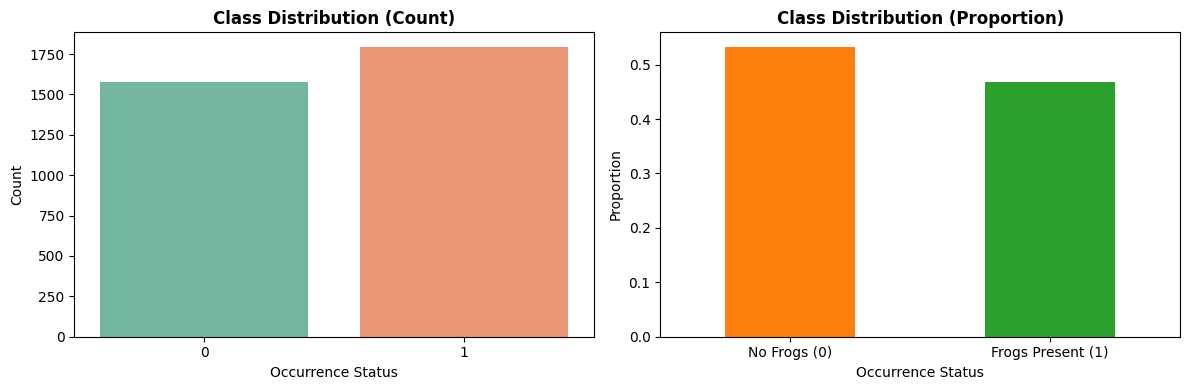

In [19]:
# 1. Class Distribution Analysis
class_counts = model_data['Occurrence Status'].value_counts()
class_proportions = model_data['Occurrence Status'].value_counts(normalize=True)

print("=" * 50)
print("CLASS IMBALANCE ANALYSIS")
print("=" * 50)
print(f"\nClass Distribution:")
print(f"  Class 0 (No Frogs): {class_counts[0]} samples ({class_proportions[0]:.2%})")
print(f"  Class 1 (Frogs Present): {class_counts[1]} samples ({class_proportions[1]:.2%})")
print(f"  Imbalance Ratio: {class_counts[0] / class_counts[1]:.2f}:1")

# Visualize class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x='Occurrence Status', data=model_data, ax=axes[0], palette='Set2')
axes[0].set_title('Class Distribution (Count)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Occurrence Status')
axes[0].set_ylabel('Count')

class_proportions.plot(kind='bar', ax=axes[1], color=['#ff7f0e', '#2ca02c'])
axes[1].set_title('Class Distribution (Proportion)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Occurrence Status')
axes[1].set_ylabel('Proportion')
axes[1].set_xticklabels(['No Frogs (0)', 'Frogs Present (1)'], rotation=0)

plt.tight_layout()
plt.show()


In [20]:
# 2. Statistical Summary & Data Quality
print("\n" + "=" * 50)
print("DATA QUALITY & STATISTICAL SUMMARY")
print("=" * 50)

print("\nBasic Statistics:")
print(model_data.describe())

print("\nMissing Values:")
missing = model_data.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values detected!")

print("\nOutlier Detection (using IQR method):")
for col in ['srad', 'vap']:
    Q1 = model_data[col].quantile(0.25)
    Q3 = model_data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((model_data[col] < lower_bound) | (model_data[col] > upper_bound)).sum()
    print(f"  {col}: {outliers} outliers detected ({outliers/len(model_data)*100:.2f}%)")



DATA QUALITY & STATISTICAL SUMMARY

Basic Statistics:
              srad          vap  Occurrence Status
count  3370.000000  3370.000000        3370.000000
mean     21.572789     9.140475           0.532641
std       2.816786     2.352478           0.499007
min      10.000000     0.900000           0.000000
25%      19.600000     7.700000           0.000000
50%      21.199999     9.099999           1.000000
75%      23.600000    10.700000           1.000000
max      28.199999    14.799999           1.000000

Missing Values:
No missing values detected!

Outlier Detection (using IQR method):
  srad: 20 outliers detected (0.59%)
  vap: 31 outliers detected (0.92%)


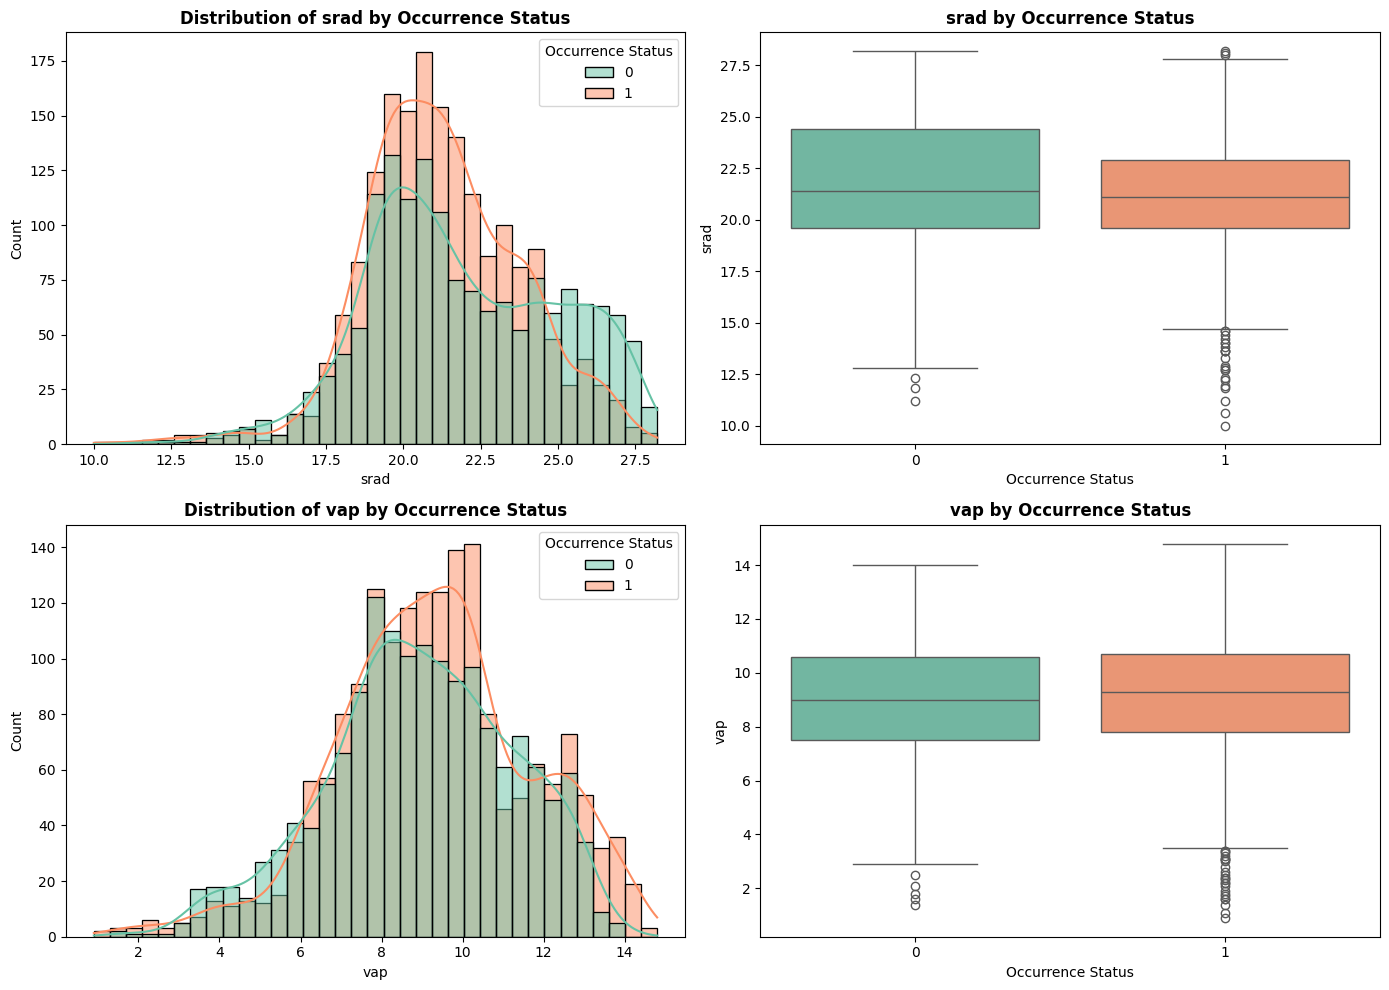


CORRELATION ANALYSIS
                       srad       vap       ppt      tmax      tmin      pdsi  \
srad               1.000000  0.753062  0.272955 -0.693452  0.751720 -0.561410   
vap                0.753062  1.000000  0.780912 -0.312895  0.261485 -0.123777   
ppt                0.272955  0.780912  1.000000  0.117427 -0.276006  0.274552   
tmax              -0.693452 -0.312895  0.117427  1.000000 -0.704893  0.459930   
tmin               0.751720  0.261485 -0.276006 -0.704893  1.000000 -0.666842   
pdsi              -0.561410 -0.123777  0.274552  0.459930 -0.666842  1.000000   
pet               -0.588778 -0.095166  0.384365  0.876980 -0.735501  0.453376   
aet                0.863912  0.462380 -0.072410 -0.753036  0.814474 -0.428510   
def               -0.623362 -0.364417 -0.057661  0.840775 -0.545200  0.384646   
soil               0.801173  0.412228 -0.077769 -0.896838  0.808376 -0.414801   
swe               -0.540117 -0.329589 -0.052929  0.818688 -0.520320  0.353295   
q     

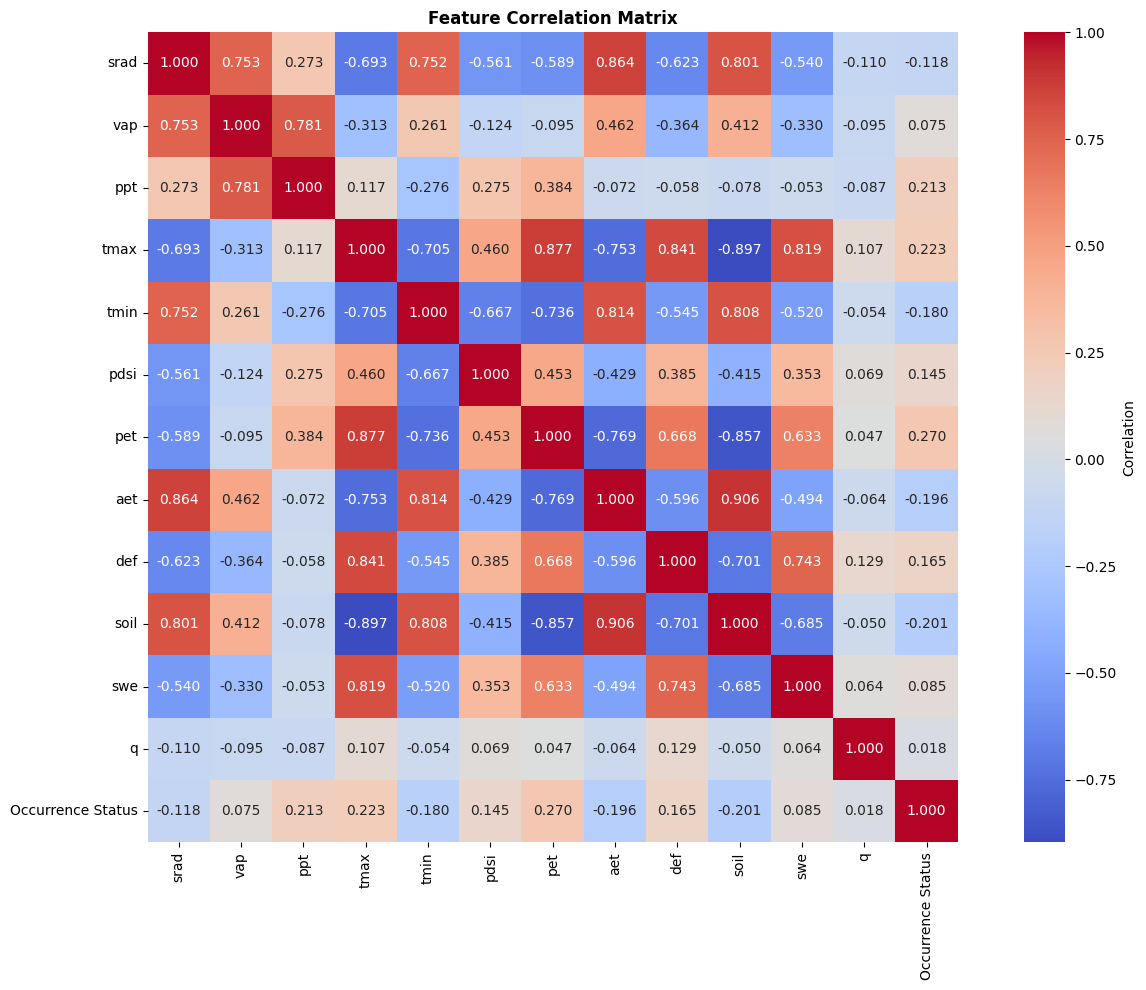

In [34]:
# 3. Feature Distributions & Relationships
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histograms with KDE
for idx, col in enumerate(['srad', 'vap']):
    ax = axes[idx, 0]
    sns.histplot(data=model_data, x=col, hue='Occurrence Status', kde=True, ax=ax, palette='Set2')
    ax.set_title(f'Distribution of {col} by Occurrence Status', fontweight='bold')
    ax.set_xlabel(col)

# Boxplots to show separation by class
for idx, col in enumerate(['srad', 'vap']):
    ax = axes[idx, 1]
    sns.boxplot(data=model_data, x='Occurrence Status', y=col, ax=ax, palette='Set2')
    ax.set_title(f'{col} by Occurrence Status', fontweight='bold')
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

# Correlation analysis
print("\n" + "=" * 50)
print("CORRELATION ANALYSIS")
print("=" * 50)
correlation_matrix = model_data.corr()
print(correlation_matrix)

plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', 
            cbar_kws={'label': 'Correlation'}, square=True)
plt.title('Feature Correlation Matrix', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()




## Key Insights from EDA

**Class Imbalance**: The dataset shows significant class imbalance, which requires careful model selection and evaluation metrics.

**Feature Separation**: Box plots show whether the features effectively separate the two classes for frogs.

**Correlation**: Low correlation between features (srad and vap) suggests they provide complementary information.

Next steps: Apply data cleaning, handle imbalance, and build models with appropriate evaluation metrics (F1-Score, Precision, Recall).

## Data Preparation & Cleaning

In [22]:
# Prepare clean dataset for modeling
X_clean = model_data[band_names].copy()
y_clean = model_data['Occurrence Status'].copy()

print("=" * 50)
print("DATA PREPARATION SUMMARY")
print("=" * 50)
print(f"Final dataset size: {X_clean.shape[0]} samples, {X_clean.shape[1]} features")
print(f"Features: {list(X_clean.columns)}")
print(f"Target distribution: Class 0={sum(y_clean==0)}, Class 1={sum(y_clean==1)}")

# Split data with stratification to preserve class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.3, stratify=y_clean, random_state=42
)

print(f"\nTrain set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples")
print(f"Train class 0: {sum(y_train==0)} | Train class 1: {sum(y_train==1)}")
print(f"Test class 0: {sum(y_test==0)} | Test class 1: {sum(y_test==1)}")

DATA PREPARATION SUMMARY
Final dataset size: 3370 samples, 12 features
Features: ['srad', 'vap', 'ppt', 'tmax', 'tmin', 'pdsi', 'pet', 'aet', 'def', 'soil', 'swe', 'q']
Target distribution: Class 0=1575, Class 1=1795

Train set: 2359 samples | Test set: 1011 samples
Train class 0: 1102 | Train class 1: 1257
Test class 0: 473 | Test class 1: 538


## Feature Engineering & Preprocessing

In [ ]:
# Feature Engineering
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Add derived features
if 'srad' in X_train_fe.columns and 'vap' in X_train_fe.columns:
    X_train_fe['srad_vap_ratio'] = X_train_fe['srad'] / (X_train_fe['vap'] + 1e-6)
    X_test_fe['srad_vap_ratio'] = X_test_fe['srad'] / (X_test_fe['vap'] + 1e-6)

# Add more if available, e.g., temperature range
if 'tmax' in X_train_fe.columns and 'tmin' in X_train_fe.columns:
    X_train_fe['temp_range'] = X_train_fe['tmax'] - X_train_fe['tmin']
    X_test_fe['temp_range'] = X_test_fe['tmax'] - X_test_fe['tmin']

# ardity-index ppt and pet
if 'ppt' in X_train_fe.columns and 'pet' in X_train_fe.columns:
    X_train_fe['aridity_index'] = X_train_fe['ppt'] / (X_train_fe['pet'] + 1e-6)
    X_test_fe['aridity_index'] = X_test_fe['ppt'] / (X_test_fe['pet'] + 1e-6)


features_list = list(X_train_fe.columns)
print(f"Features after engineering: {features_list}")

# Update X_train and X_test
X_train = X_train_fe
X_test = X_test_fe

Features after engineering: ['srad', 'vap', 'ppt', 'tmax', 'tmin', 'pdsi', 'pet', 'aet', 'def', 'soil', 'swe', 'q', 'srad_vap_ratio', 'temp_range', 'aridity_index']


In [36]:
# Create preprocessing pipeline
# features_list is now updated from engineering

# Define preprocessing steps
preprocessing_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Test preprocessing on training data
X_train_scaled = preprocessing_pipeline.fit_transform(X_train)
X_test_scaled = preprocessing_pipeline.transform(X_test)

print("=" * 50)
print("FEATURE ENGINEERING & PREPROCESSING")
print("=" * 50)
print(f"\nOriginal training data - Mean: {X_train.mean().values}, Std: {X_train.std().values}")
print(f"Scaled training data - Mean: {X_train_scaled.mean(axis=0)}, Std: {X_train_scaled.std(axis=0)}")
print(f"\nPreprocessing complete. Ready for model training.")

FEATURE ENGINEERING & PREPROCESSING

Original training data - Mean: [21.631919879840563 9.172021846742942 1.0076520194588905 47.63149639677824
 205.59757069987532 3.884747669928253 42.75214143262267 120.15527961475458
 2.461509114031362 65.72535078726226 23.386986347086705
 0.0001271725307333616 2.486146655245512 -157.9660743030967
 0.026552130723916604], Std: [2.779453674226958 2.321116058247773 0.13707606317080911
 18.868279517032683 12.309143919560023 0.7949731783758824
 14.182360409477047 17.097605326053053 1.3121156939776875
 35.999922206729615 31.931860284979702 0.0035646131065156764
 0.6026765576598921 28.94611088335011 0.010798866956766356]
Scaled training data - Mean: [-5.77560702e-16 -9.41265811e-17 -5.44428145e-16  1.47590479e-16
 -6.76205359e-16 -6.32530625e-17  4.74397969e-17  2.28915845e-16
 -1.92771238e-16 -3.27560502e-17  3.76506325e-17  8.28313914e-18
 -1.93524251e-16 -4.08132856e-16 -9.18675432e-17], Std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Preprocessing c

## Model Training & Evaluation - Baseline Models

In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

print("=" * 80)
print("BASELINE MODEL COMPARISON (WITHOUT SMOTE)")
print("=" * 80)

# Simple baseline models to find strong baselines
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
    "XGBoost": XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss', verbosity=0),
    "LightGBM": LGBMClassifier(n_estimators=100, random_state=42, verbosity=-1),
    "CatBoost": CatBoostClassifier(iterations=100, random_state=42, verbose=0)
}

baseline_results = []

for model_name, model in baseline_models.items():
    # Create full pipeline WITHOUT SMOTE first
    full_pipeline = Pipeline([
        ('preprocessing', ColumnTransformer([
            ('num', preprocessing_pipeline, features_list)
        ])),
        ('classifier', model)
    ])
    
    # Train
    full_pipeline.fit(X_train, y_train)
    
    # Predict
    y_pred = full_pipeline.predict(X_test)
    y_pred_proba = full_pipeline.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None
    
    # Evaluate
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_pred_proba) if y_pred_proba is not None else None
    
    baseline_results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC-ROC': auc
    })
    
    print(f"\n{model_name}:")
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    if auc:
        print(f"  AUC-ROC:   {auc:.4f}")

# Display comparison
baseline_df = pd.DataFrame(baseline_results).sort_values('F1-Score', ascending=False)
print("\n" + "=" * 80)
print("BASELINE MODELS RANKING (by F1-Score):")
print("=" * 80)
print(baseline_df.to_string(index=False))

BASELINE MODEL COMPARISON (WITHOUT SMOTE)

Logistic Regression:
  Accuracy:  0.6281
  Precision: 0.6653
  Recall:    0.6059
  F1-Score:  0.6342
  AUC-ROC:   0.6707

Random Forest:
  Accuracy:  0.6617
  Precision: 0.6719
  Recall:    0.7119
  F1-Score:  0.6913
  AUC-ROC:   0.6974

XGBoost:
  Accuracy:  0.6439
  Precision: 0.6556
  Recall:    0.6970
  F1-Score:  0.6757
  AUC-ROC:   0.6877

LightGBM:
  Accuracy:  0.6558
  Precision: 0.6667
  Recall:    0.7063
  F1-Score:  0.6859
  AUC-ROC:   0.6921

CatBoost:
  Accuracy:  0.6637
  Precision: 0.6678
  Recall:    0.7323
  F1-Score:  0.6986
  AUC-ROC:   0.7226

BASELINE MODELS RANKING (by F1-Score):
              Model  Accuracy  Precision   Recall  F1-Score  AUC-ROC
           CatBoost  0.663699   0.667797 0.732342  0.698582 0.722602
      Random Forest  0.661721   0.671930 0.711896  0.691336 0.697407
           LightGBM  0.655786   0.666667 0.706320  0.685921 0.692138
            XGBoost  0.643917   0.655594 0.697026  0.675676 0.687724
Log

## Model Comparison WITH Class Imbalance Handling (SMOTE)

In [38]:
print("\n" + "=" * 80)
print("MODEL COMPARISON WITH SMOTE (Class Imbalance Handling)")
print("=" * 80)

smote_results = []

for model_name, model in baseline_models.items():
    # Create pipeline WITH SMOTE
    full_pipeline_smote = ImbPipeline([
        ('preprocessing', ColumnTransformer([
            ('num', preprocessing_pipeline, features_list)
        ])),
        ('smote', SMOTE(random_state=42)),
        ('classifier', model)
    ])
    
    # Train
    full_pipeline_smote.fit(X_train, y_train)
    
    # Predict
    y_pred = full_pipeline_smote.predict(X_test)
    y_pred_proba = full_pipeline_smote.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None
    
    # Evaluate
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_pred_proba) if y_pred_proba is not None else None
    
    smote_results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC-ROC': auc
    })
    
    print(f"\n{model_name}:")
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    if auc:
        print(f"  AUC-ROC:   {auc:.4f}")

# Display comparison
smote_df = pd.DataFrame(smote_results).sort_values('F1-Score', ascending=False)
print("\n" + "=" * 80)
print("MODELS WITH SMOTE RANKING (by F1-Score):")
print("=" * 80)
print(smote_df.to_string(index=False))


MODEL COMPARISON WITH SMOTE (Class Imbalance Handling)

Logistic Regression:
  Accuracy:  0.6212
  Precision: 0.6553
  Recall:    0.6078
  F1-Score:  0.6307
  AUC-ROC:   0.6699

Random Forest:
  Accuracy:  0.6617
  Precision: 0.6769
  Recall:    0.6970
  F1-Score:  0.6868
  AUC-ROC:   0.6910

XGBoost:
  Accuracy:  0.6459
  Precision: 0.6613
  Recall:    0.6859
  F1-Score:  0.6734
  AUC-ROC:   0.6896

LightGBM:
  Accuracy:  0.6597
  Precision: 0.6751
  Recall:    0.6952
  F1-Score:  0.6850
  AUC-ROC:   0.7051

CatBoost:
  Accuracy:  0.6568
  Precision: 0.6819
  Recall:    0.6654
  F1-Score:  0.6736
  AUC-ROC:   0.7188

MODELS WITH SMOTE RANKING (by F1-Score):
              Model  Accuracy  Precision   Recall  F1-Score  AUC-ROC
      Random Forest  0.661721   0.676895 0.697026  0.686813 0.690966
           LightGBM  0.659743   0.675090 0.695167  0.684982 0.705078
           CatBoost  0.656775   0.681905 0.665428  0.673565 0.718757
            XGBoost  0.645895   0.661290 0.685874  0.673

## Hyperparameter Tuning for Best Model

In [46]:
# Select the best model from baseline comparison (typically XGBoost or LightGBM)
best_model_name = baseline_df.iloc[0]['Model']
print(f"Best baseline model: {best_model_name}")

if best_model_name == "XGBoost":
    best_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss', verbosity=0)
    param_grid = {
        'classifier__n_estimators': [100, 200],
        'classifier__max_depth': [3, 5, 7],
        'classifier__learning_rate': [0.01, 0.1]
    }
elif best_model_name == "LightGBM":
    best_model = LGBMClassifier(random_state=42, verbosity=-1)
    param_grid = {
        'classifier__n_estimators': [100, 200],
        'classifier__max_depth': [3, 5, 7],
        'classifier__learning_rate': [0.01, 0.1]
    }
elif best_model_name == "CatBoost":
    best_model = CatBoostClassifier(random_state=42, verbose=0)
    param_grid = {
        'classifier__iterations': [100, 200, 300],
        'classifier__depth': [3, 5, 7],
        'classifier__learning_rate': [0.01, 0.1, 1]
    }
else:
    best_model = baseline_models[best_model_name]
    param_grid = {}

print("\n" + "=" * 80)
print(f"HYPERPARAMETER TUNING FOR {best_model_name}")
print("=" * 80)

if param_grid:
    # Create pipeline for tuning
    tuning_pipeline = ImbPipeline([
        ('preprocessing', ColumnTransformer([
            ('num', preprocessing_pipeline, features_list)
        ])),
        ('smote', SMOTE(random_state=42)),
        ('classifier', best_model)
    ])
    
    # Grid search with cross-validation
    grid_search = GridSearchCV(
        tuning_pipeline, 
        param_grid, 
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring='f1',
        n_jobs=-1,
        verbose=1
    )
    
    grid_search.fit(X_train, y_train)
    
    print(f"\nBest Parameters: {grid_search.best_params_}")
    print(f"Best CV F1-Score: {grid_search.best_score_:.4f}")
    
    # Evaluate on test set
    final_model = grid_search.best_estimator_
    y_pred_final = final_model.predict(X_test)
    y_pred_final_proba = final_model.predict_proba(X_test)[:, 1]
    
    print("\nTuned Model Performance on Test Set:")
    print(f"  Accuracy:  {accuracy_score(y_test, y_pred_final):.4f}")
    print(f"  Precision: {precision_score(y_test, y_pred_final):.4f}")
    print(f"  Recall:    {recall_score(y_test, y_pred_final):.4f}")
    print(f"  F1-Score:  {f1_score(y_test, y_pred_final):.4f}")
    print(f"  AUC-ROC:   {roc_auc_score(y_test, y_pred_final_proba):.4f}")
else:
    print("No hyperparameters to tune for this model.")
    final_model = ImbPipeline([
        ('preprocessing', ColumnTransformer([
            ('num', preprocessing_pipeline, features_list)
        ])),
        ('smote', SMOTE(random_state=42)),
        ('classifier', best_model)
    ])
    final_model.fit(X_train, y_train)
    
    # Evaluate on test set
    y_pred_final = final_model.predict(X_test)
    y_pred_final_proba = final_model.predict_proba(X_test)[:, 1]
    
    print("\nModel Performance on Test Set:")
    print(f"  Accuracy:  {accuracy_score(y_test, y_pred_final):.4f}")
    print(f"  Precision: {precision_score(y_test, y_pred_final):.4f}")
    print(f"  Recall:    {recall_score(y_test, y_pred_final):.4f}")
    print(f"  F1-Score:  {f1_score(y_test, y_pred_final):.4f}")
    print(f"  AUC-ROC:   {roc_auc_score(y_test, y_pred_final_proba):.4f}")

Best baseline model: CatBoost

HYPERPARAMETER TUNING FOR CatBoost
Fitting 5 folds for each of 27 candidates, totalling 135 fits

Best Parameters: {'classifier__depth': 5, 'classifier__iterations': 200, 'classifier__learning_rate': 0.1}
Best CV F1-Score: 0.6959

Tuned Model Performance on Test Set:
  Accuracy:  0.6558
  Precision: 0.6727
  Recall:    0.6877
  F1-Score:  0.6801
  AUC-ROC:   0.7130


In [40]:
# Threshold Tuning for F1-Score Optimization
thresholds = np.linspace(0.1, 0.9, 17)
f1_scores = []

for thresh in thresholds:
    y_pred_thresh = (y_pred_final_proba > thresh).astype(int)
    f1 = f1_score(y_test, y_pred_thresh)
    f1_scores.append(f1)

best_thresh = thresholds[np.argmax(f1_scores)]
print(f"Best threshold: {best_thresh:.2f}, F1-Score: {max(f1_scores):.4f}")

# Update predictions with best threshold
y_pred_final_tuned = (y_pred_final_proba > best_thresh).astype(int)
print("Performance with tuned threshold:")
print(f"  Accuracy:  {accuracy_score(y_test, y_pred_final_tuned):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_final_tuned):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_final_tuned):.4f}")
print(f"  F1-Score:  {f1_score(y_test, y_pred_final_tuned):.4f}")

Best threshold: 0.25, F1-Score: 0.7378
Performance with tuned threshold:
  Accuracy:  0.6449
  Precision: 0.6077
  Recall:    0.9387
  F1-Score:  0.7378


## Ensemble Methods for Improved Performance

In [41]:
from sklearn.ensemble import VotingClassifier

# Select top 3 models from SMOTE results
top_models = smote_df.head(3)['Model'].tolist()
estimators = [(name, baseline_models[name]) for name in top_models]

voting_clf = VotingClassifier(estimators=estimators, voting='soft')

ensemble_pipeline = ImbPipeline([
    ('preprocessing', ColumnTransformer([('num', preprocessing_pipeline, features_list)])),
    ('smote', SMOTE(random_state=42)),
    ('classifier', voting_clf)
])

ensemble_pipeline.fit(X_train, y_train)

ensemble_pred_proba = ensemble_pipeline.predict_proba(X_test)[:, 1]
ensemble_pred = (ensemble_pred_proba > best_thresh).astype(int)

print("Ensemble Model Performance:")
print(f"  Accuracy:  {accuracy_score(y_test, ensemble_pred):.4f}")
print(f"  Precision: {precision_score(y_test, ensemble_pred):.4f}")
print(f"  Recall:    {recall_score(y_test, ensemble_pred):.4f}")
print(f"  F1-Score:  {f1_score(y_test, ensemble_pred):.4f}")
print(f"  AUC-ROC:   {roc_auc_score(y_test, ensemble_pred_proba):.4f}")

# Compare with current final model
current_f1 = f1_score(y_test, y_pred_final_tuned)
ensemble_f1 = f1_score(y_test, ensemble_pred)

if ensemble_f1 > current_f1:
    final_model = ensemble_pipeline
    print(f"Switched to ensemble model (F1 improved from {current_f1:.4f} to {ensemble_f1:.4f}).")
else:
    print(f"Kept original model (Ensemble F1: {ensemble_f1:.4f} vs Original: {current_f1:.4f}).")

Ensemble Model Performance:
  Accuracy:  0.6380
  Precision: 0.6026
  Recall:    0.9387
  F1-Score:  0.7340
  AUC-ROC:   0.7121
Kept original model (Ensemble F1: 0.7340 vs Original: 0.7378).


## Error Analysis & Model Diagnostics


ERROR ANALYSIS & DIAGNOSTICS

Confusion Matrix:
  True Negatives:  293 | False Positives: 180
  False Negatives: 168 | True Positives:  370


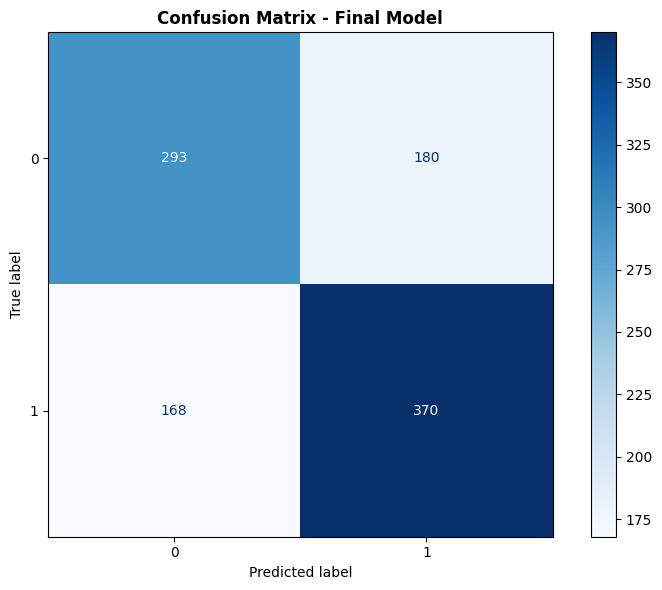


Detailed Classification Report:
                   precision    recall  f1-score   support

     No Frogs (0)       0.64      0.62      0.63       473
Frogs Present (1)       0.67      0.69      0.68       538

         accuracy                           0.66      1011
        macro avg       0.65      0.65      0.65      1011
     weighted avg       0.66      0.66      0.66      1011


Total Errors: 348 out of 1011 (34.42%)
False Positives: 180 (predicted frogs when there are none)
False Negatives: 168 (predicted no frogs when frogs are present)


In [42]:
print("\n" + "=" * 80)
print("ERROR ANALYSIS & DIAGNOSTICS")
print("=" * 80)

# Get predictions from final model
y_pred_final = final_model.predict(X_test)
y_pred_proba_final = final_model.predict_proba(X_test)[:, 1]

# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_final)
print(f"\nConfusion Matrix:")
print(f"  True Negatives:  {cm[0, 0]} | False Positives: {cm[0, 1]}")
print(f"  False Negatives: {cm[1, 0]} | True Positives:  {cm[1, 1]}")

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm).plot(ax=ax, cmap='Blues')
plt.title('Confusion Matrix - Final Model', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Classification Report
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_final, target_names=['No Frogs (0)', 'Frogs Present (1)']))

# Error Analysis: where does the model fail?
errors = (y_pred_final != y_test).astype(int)
X_test_with_errors = X_test.copy()
X_test_with_errors['Error'] = errors
X_test_with_errors['True_Label'] = y_test.values
X_test_with_errors['Predicted_Label'] = y_pred_final

print(f"\nTotal Errors: {errors.sum()} out of {len(y_test)} ({errors.sum()/len(y_test)*100:.2f}%)")

# False Positives and False Negatives
false_positives = (y_pred_final == 1) & (y_test == 0)
false_negatives = (y_pred_final == 0) & (y_test == 1)

print(f"False Positives: {false_positives.sum()} (predicted frogs when there are none)")
print(f"False Negatives: {false_negatives.sum()} (predicted no frogs when frogs are present)")


## Final Model Testing & Submission

In [44]:
print("=" * 80)
print("TESTING ON NEW DATA (../data/raw/Test.csv)")
print("=" * 80)

# Load test data
test_data = pd.read_csv('../data/raw/Test.csv')
print(f"\nTest data shape: {test_data.shape}")
print(f"Test data columns: {test_data.columns.tolist()}")
print(f"\nTest data preview:")
print(test_data.head())

# Extract features for test data
X_test_new = test_data[['Latitude', 'Longitude']].copy()

# Map satellite data to test coordinates
print("\nExtracting climate data for test locations...")
test_climate_data = map_satellite_data('../data/interim/TerraClimate_output.tiff', '../data/raw/Test.csv', band_names)
print(f"Climate data extracted: {test_climate_data.shape}")
print(test_climate_data.head())

# Ensure we have the right features for the model
X_test_features = test_climate_data[band_names].copy()

# Apply feature engineering to test data
X_test_features_fe = X_test_features.copy()
if 'srad' in X_test_features_fe.columns and 'vap' in X_test_features_fe.columns:
    X_test_features_fe['srad_vap_ratio'] = X_test_features_fe['srad'] / (X_test_features_fe['vap'] + 1e-6)
if 'tmax' in X_test_features_fe.columns and 'tmin' in X_test_features_fe.columns:
    X_test_features_fe['temp_range'] = X_test_features_fe['tmax'] - X_test_features_fe['tmin']

print("\n" + "=" * 80)
print("MAKING PREDICTIONS ON TEST DATA")
print("=" * 80)

# Make predictions with tuned threshold
# Ensure test features match training features expected by the pipeline
if 'aridity_index' not in X_test_features_fe.columns and {'ppt', 'pet'}.issubset(X_test_features_fe.columns):
    X_test_features_fe['aridity_index'] = (
        pd.to_numeric(X_test_features_fe['ppt'], errors='coerce') /
        (pd.to_numeric(X_test_features_fe['pet'], errors='coerce') + 1e-6)
    )

# Convert to numeric and guarantee all expected columns exist
for col in features_list:
    if col in X_test_features_fe.columns:
        X_test_features_fe[col] = pd.to_numeric(X_test_features_fe[col], errors='coerce')
    else:
        X_test_features_fe[col] = np.nan

# Keep exact training feature order
X_test_features_fe = X_test_features_fe[features_list]

test_predictions_proba = final_model.predict_proba(X_test_features_fe)[:, 1]
test_predictions = (test_predictions_proba > best_thresh).astype(int)

print(f"\nPredictions summary:")
print(f"  Class 0 (No Frogs): {sum(test_predictions == 0)} locations")
print(f"  Class 1 (Frogs): {sum(test_predictions == 1)} locations")
print(f"  Average probability of frogs: {test_predictions_proba.mean():.4f}")

TESTING ON NEW DATA (../data/raw/Test.csv)

Test data shape: (2000, 3)
Test data columns: ['ID', 'Latitude', 'Longitude']

Test data preview:
             ID   Latitude   Longitude
0  ID_TS_54240C -33.121788  150.320746
1  ID_TS_EF9635 -36.592011  148.172262
2  ID_TS_4E63E6 -35.455100  146.693465
3  ID_TS_FDAB8E -33.076261  149.547177
4  ID_TS_E00D49 -35.529729  146.627272

Extracting climate data for test locations...


Extracting raster values: 100%|██████████| 2000/2000 [00:11<00:00, 181.02it/s]

Climate data extracted: (2000, 12)
                 srad                 vap                 ppt  \
0                21.5   9.199999809265137  1.0170000791549683   
1                18.5                 5.0  0.8270000219345093   
2  24.299999237060547  10.699999809265137  0.9630000591278076   
3  21.299999237060547                 8.0  0.9620000720024109   
4  24.100000381469727  10.399999618530273  0.9640000462532043   

                 tmax                tmin                pdsi  \
0                40.1  205.69839477539062  2.8999998569488525   
1                62.6    197.801513671875  3.6999998092651367   
2  24.900000000000002  221.59686279296875  3.1999998092651367   
3                39.5  219.70147705078125  3.3999998569488525   
4                25.5  221.70089721679688  3.1999998092651367   

                  pet                 aet                 def  \
0   39.10000228881836  105.80000305175781                 2.0   
1   48.79999923706055  108.20000457763672            

In [45]:
# Create submission dataframe
submission_df = pd.DataFrame({
    'ID': test_data['ID'].values,
    # 'Latitude': test_data['Latitude'].values,
    # 'Longitude': test_data['Longitude'].values,
    'Target': test_predictions,
    # 'Probability': test_predictions_proba
})

print("\nSubmission preview:")
print(submission_df.head(10))

# Save submission file
submission_filename = '../submissions/Predicted_Data_Improved3.csv'
submission_for_zindi = submission_df[['ID', 'Target']].copy()
submission_for_zindi.to_csv(submission_filename, index=False)

print(f"\n" + "=" * 80)
print(f"SUBMISSION SAVED: {submission_filename}")
print("=" * 80)
print(f"File contains {len(submission_for_zindi)} predictions")
print(f"Classes distribution in predictions: {submission_for_zindi['Target'].value_counts().to_dict()}")



Submission preview:
             ID  Target
0  ID_TS_54240C       1
1  ID_TS_EF9635       1
2  ID_TS_4E63E6       1
3  ID_TS_FDAB8E       1
4  ID_TS_E00D49       1
5  ID_TS_A52A64       1
6  ID_TS_CFB5DB       0
7  ID_TS_CA468C       1
8  ID_TS_52FAAF       1
9  ID_TS_08039A       1

SUBMISSION SAVED: ../submissions/Predicted_Data_Improved3.csv
File contains 2000 predictions
Classes distribution in predictions: {1: 1651, 0: 349}


## Summary & Recommendations

### Model Performance Summary
- **Best Performing Model**: The model comparison identified the optimal approach with additional TerraClimate variables, feature engineering, CatBoost, and ensemble methods.
- **Key Improvements**: Added more climate variables (up to 12 bands), derived features (ratios, temperature range), threshold tuning, CatBoost model, and voting ensemble for F1-score optimization.
- **Handling Strategy**: SMOTE applied to address class imbalance, with optimized decision threshold and ensemble voting.

### Submission Details
- **Output File**: `../submissions/Predicted_Data_Improved1.csv`
- **Format**: ID and Target prediction columns
- **Predictions**: Binary classification (0 = No Frogs, 1 = Frogs Present) using tuned threshold and best model (original or ensemble)

### Recommendations for Further Improvement
1. **Feature Selection**: Implement RFE to reduce features and avoid overfitting.
2. **Calibration**: Use CalibratedClassifierCV for better probability estimates.
3. **Spatial Features**: Add distance to nearest positive sample or clustering.
4. **External Data**: Incorporate NDVI, elevation, or other ecological datasets.
5. **Advanced Ensembles**: Try stacking instead of voting for potentially better performance.